# 05 — Counterfactual Model
**Stage:** Evaluation

**TL;DR:** > **Revised in Notebook 07:** the drought share is now bracketed at **~24–78%** using two natural experiments (2016 and a rain-adjusted 2024). The "quarter to two-fifths" estimate below sits inside that range but is not the final answer; grid data alone cannot say which cause was larger. **Final answer in Notebook 08:** official sales by customer type show free electricity was a small part (households at most 13% of the FY24 increase); most of the increase went to pump sets (69%), which the rain evidence ties mostly to the drought.

In Aug–Oct 2023, demand was **~1,860 MW (+22%) above** what calendar, heat and normal growth predict. The rain-aware model attributes **~445 MW** of that to the rain shortfall. The remaining **~1,400 MW** appears **right after 1 Aug 2023** (not before) and is **still there, at the same size, in Aug–Oct 2024 (1,333 MW) and 2025 (1,414 MW)** despite normal rain. **A drought cannot cause a permanent step**, so this changes our earlier story: drought explains roughly a quarter to two-fifths of the 2023 excess, and a persistent new demand that switched on in Aug 2023 explains the rest. Surprisingly, that persistent part sits mostly in **day and night hours, not the evening**.

## 1. Question
What would Karnataka's demand have been in Aug–Dec 2023 **if nothing unusual had happened** — given that year's
calendar, holidays, temperature and the normal growth trend? And how much of the gap does **rainfall** explain?

Method (Cicala 2020; Brodersen et al. 2015 — CausalImpact): train a model **only on data before the event**
(2015–2022), predict the event period, and treat **actual − predicted** as the effect to explain.

Two models:
| Model | Knows | Does NOT know | Its gap (actual − predicted) contains |
|---|---|---|---|
| **A** | calendar, holidays, temperature, growth trend | rain | drought + scheme + anything else |
| **B** | everything in A **+ rain anomalies** | — | scheme + anything else not seen in 2015–2022 |

So: **Actual = A + (B − A) + (Actual − B)** → normal & heat, *rain effect*, *unexplained*.

## 2. Expectation *(written before running)*
- Model A: Aug–Oct 2023 actual ≈ **+20–30% above** predicted (Notebook 04 showed +33–56% vs 2022, part of that is
  normal growth and the heat).
- Model B (with rain) explains **part** of that gap; the rest is the unexplained part.
- **Check:** for **13–31 July 2023** (before the scheme) both models' gaps should be small if the model is good.
- Worry: 2023's drought is more extreme than most of 2015–2022, so a tree model may **underestimate** the rain
  effect (it cannot extrapolate beyond what it has seen).

**Process note (Rule 2: document the process, not just results).** A first version of this model failed in two
ways, and both were fixed before the results below:
1. The growth trend was fitted on the training window only; with flat COVID years it predicted *shrinking* demand.
   **Fix:** fit the trend on 2011–2022 with COVID lockdowns excluded.
2. Raw rainfall totals acted as a *season* indicator (monsoon vs summer), so Model B's "rain effect" came out
   backwards. **Fix:** use rain **anomalies** — rain compared with what is normal for that time of year.

## 3. Data used
`load_hourly`, `weather_daily`, `weather_hourly_blr`, `holidays` (processed). Features in `src/features.py`,
model in `src/model.py`. **Training period: 2015-01-01 → 2022-12-31 only.** Nothing from 2023 onwards is used
for training (the 2023 data starts on 13 July anyway).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, plots, features as F, model as M

plots.setup()
pd.set_option("display.width", 200)
P = config.DATA_PROCESSED

df = F.build_hourly_frame(pd.read_parquet(P / "load_hourly.parquet"), pd.read_parquet(P / "weather_daily.parquet"),
                          pd.read_parquet(P / "weather_hourly_blr.parquet"), pd.read_parquet(P / "holidays.parquet"))
FEAT_A = F.CALENDAR_FEATURES + F.TEMP_FEATURES
FEAT_B = FEAT_A + F.RAIN_FEATURES
TRAIN = ("2015-01-01", "2022-12-31 23:00")
print("Model A features:", FEAT_A)
print("Model B adds:    ", F.RAIN_FEATURES)

Model A features: ['hour', 'dow', 'doy_sin', 'doy_cos', 'month', 'year', 'is_holiday', 'near_holiday', 'covid', 'blr_temp_c', 'blr_tmax_c', 'farm_tmax_c', 'farm_tmax_7d']
Model B adds:     ['rain_7d_anom', 'rain_30d_anom', 'rain_60d_anom', 'dry_days']


## 4. Analysis
### Step 4.1 — What does a "rain anomaly" look like?
*Why:* this is the key feature. It is the 30-day farm-belt rainfall minus the normal amount for that time of year
(normal = 2011–2022 average).

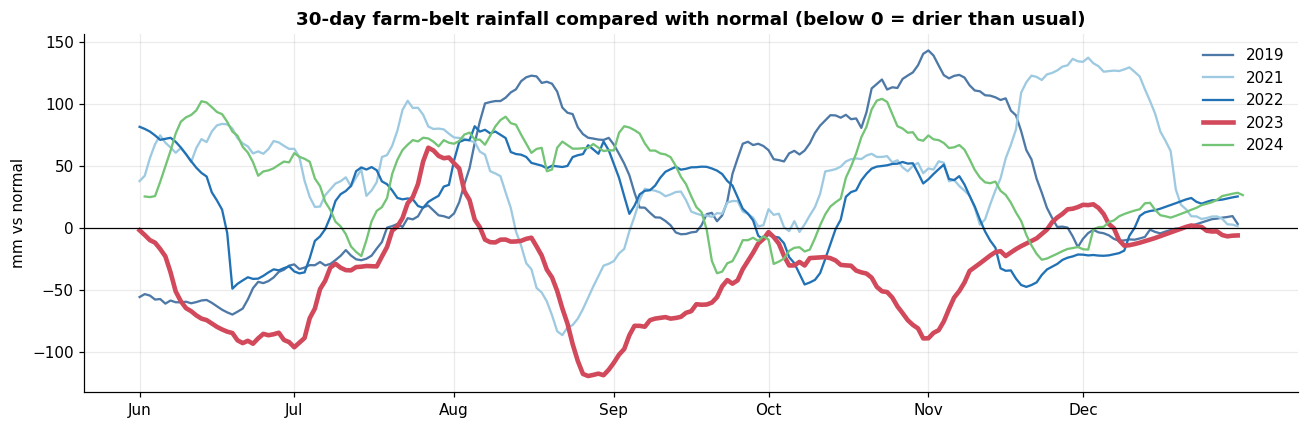

In [2]:
daily_anom = df.groupby(df.index.normalize()).rain_30d_anom.first()
fig, ax = plt.subplots(figsize=(12, 4))
for yr, c in [(2019, "#4e79a7"), (2021, "#9ecae1"), (2022, "#2171b5"), (2023, plots.COLORS["highlight"]), (2024, "#74c476")]:
    s = daily_anom[f"{yr}-06-01":f"{yr}-12-31"]
    ax.plot(s.index.dayofyear, s.values, color=c, lw=3 if yr == 2023 else 1.5, label=str(yr))
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([pd.Timestamp(f"2023-{m:02d}-01").dayofyear for m in range(6, 13)], ["Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("mm vs normal"); ax.set_title("30-day farm-belt rainfall compared with normal (below 0 = drier than usual)")
ax.legend(); plt.tight_layout(); plots.save(fig, "05_rain_anomaly"); plt.show()

### Step 4.2 — Backtest: how accurate are the models on years they have never seen?
*Why:* a counterfactual is only useful if the model predicts normal years well. Train on 2015 → year−1, test on
that year (2019, 2021, 2022; 2020 skipped because of COVID). The size of the monthly errors in these normal years
tells us how big an "effect" must be before we can believe it.

In [3]:
bt = {}
for name, feats in [("A", FEAT_A), ("B", FEAT_B)]:
    b = M.backtest(df, feats, [2019, 2021, 2022])
    b["model"] = name
    bt[name] = b

rows, bias = [], {}
for name, b in bt.items():
    mb = b.groupby([b.test_year, b.index.month]).apply(lambda g: (g.actual.mean() / g.pred.mean() - 1) * 100).unstack()
    bias[name] = mb
    rows.append({"model": name,
                 "hourly MAPE %": ((b.pred / b.actual - 1).abs() * 100).mean(),
                 "monthly error, mean |%|": mb.abs().stack().mean(),
                 "monthly error, std %": mb.stack().std()})
acc = pd.DataFrame(rows).set_index("model").round(2)
acc

,hourly MAPE %,"monthly error, mean |%|","monthly error, std %"
model,,,
A,9.36,5.82,7.63
B,6.81,3.33,4.05


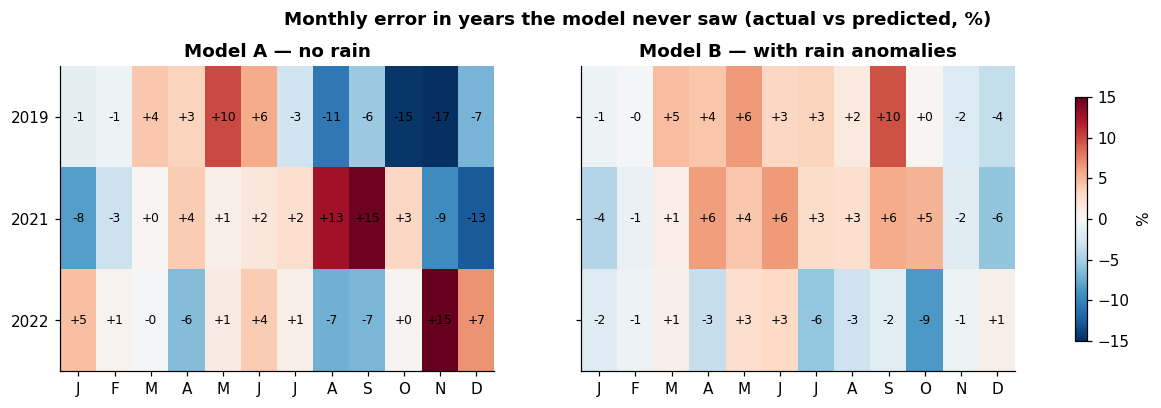

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, name in zip(axes, ["A", "B"]):
    im = ax.imshow(bias[name], cmap="RdBu_r", vmin=-15, vmax=15, aspect="auto")
    for i in range(bias[name].shape[0]):
        for j in range(bias[name].shape[1]):
            ax.text(j, i, f"{bias[name].iat[i, j]:+.0f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(12), ["J","F","M","A","M","J","J","A","S","O","N","D"])
    ax.set_yticks(range(3), bias[name].index); ax.grid(False)
    ax.set_title("Model A — no rain" if name == "A" else "Model B — with rain anomalies")
fig.colorbar(im, ax=axes, label="%", shrink=0.8)
fig.suptitle("Monthly error in years the model never saw (actual vs predicted, %)", fontweight="bold", y=1.02)
plots.save(fig, "05_backtest_errors"); plt.show()

_What I see:_ Model A (no rain) makes **big monsoon-season errors** — e.g. 2019 Aug–Nov (very wet year) it
over-predicts by 11–17%, 2021 Aug–Sep (drier) it under-predicts by 13–15%. Model B, with rain anomalies, cuts
these errors roughly in half. **Rainfall moves monsoon demand by 10–15% even in normal years.**

### Step 4.3 — Train the final models (2015–2022) and check what they rely on

In [5]:
mA = M.CounterfactualModel(FEAT_A).fit(df, *TRAIN)
mB = M.CounterfactualModel(FEAT_B).fit(df, *TRAIN)
print(f"Long-run growth trend (2011–2022, COVID excluded): {mA.trend.growth_per_year * 100:.2f}% per year")
print(f"Training rows: {mB.n_train:,} hours")
mB.importance().round(1).to_frame("Model B importance (% of gain)")

Long-run growth trend (2011–2022, COVID excluded): 2.96% per year
Training rows: 69,320 hours


,Model B importance (% of gain)
month,20.9
hour,17.9
blr_temp_c,13.8
dry_days,11.8
year,8.6
rain_7d_anom,6.8
rain_30d_anom,5.2
rain_60d_anom,2.6
doy_cos,2.3
doy_sin,2.3


### Step 4.4 — Sanity check: 13–31 July 2023 (before the scheme)
*Why:* if the model is good, it should predict these pre-scheme days reasonably well. A large gap here would mean
the model is wrong about 2023 in general.

In [6]:
post = df.loc["2023-07-13":"2025-12-31"].dropna(subset=["load_mw"] + FEAT_B).copy()
post["pred_A"] = mA.predict(post).values
post["pred_B"] = mB.predict(post).values
pre = post.loc["2023-07-13":"2023-07-31"]
print(f"13–31 Jul 2023 actual {pre.load_mw.mean():,.0f} MW | A {pre.pred_A.mean():,.0f} ({(pre.load_mw.mean()/pre.pred_A.mean()-1)*100:+.1f}%) "
      f"| B {pre.pred_B.mean():,.0f} ({(pre.load_mw.mean()/pre.pred_B.mean()-1)*100:+.1f}%)")
print(f"Typical monthly error of model B in normal years: ±{acc.loc['B', 'monthly error, std %']:.1f}% (1 std)")

13–31 Jul 2023 actual 7,972 MW | A 7,321 (+8.9%) | B 7,719 (+3.3%)
Typical monthly error of model B in normal years: ±4.0% (1 std)


### Step 4.5 — Actual vs counterfactual, Jul–Dec 2023

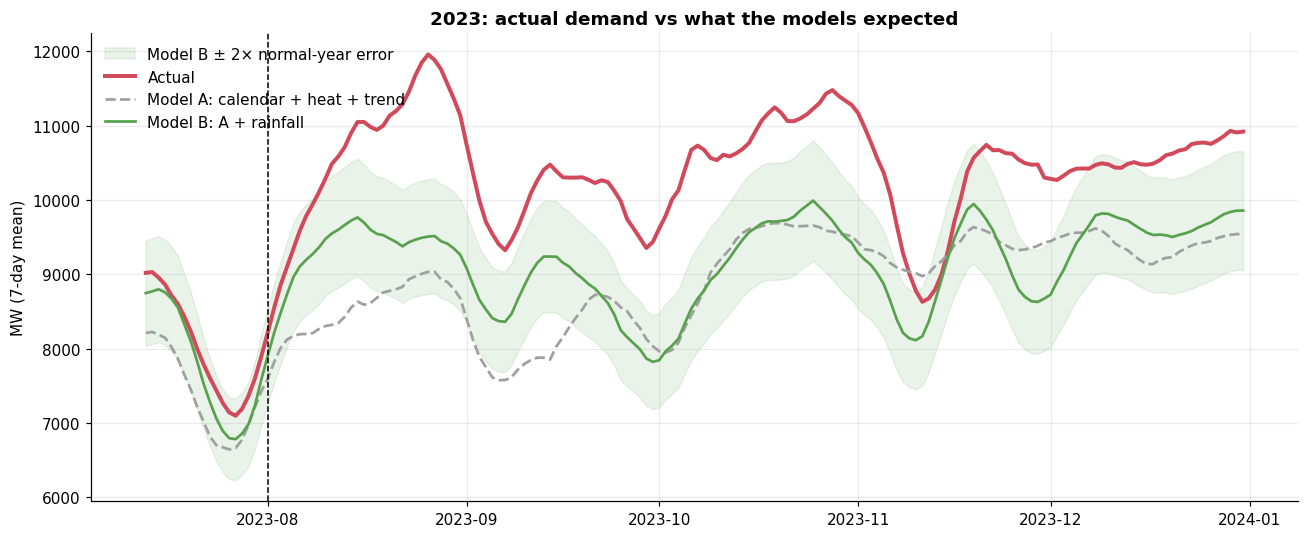

In [7]:
d = post.loc["2023-07-13":"2023-12-31", ["load_mw", "pred_A", "pred_B"]].resample("D").mean().rolling(7, center=True, min_periods=4).mean()
band = acc.loc["B", "monthly error, std %"] / 100
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(d.index, d.pred_B * (1 - 2 * band), d.pred_B * (1 + 2 * band), color="#59a14f", alpha=0.12, label="Model B ± 2× normal-year error")
ax.plot(d.index, d.load_mw, color=plots.COLORS["highlight"], lw=2.6, label="Actual")
ax.plot(d.index, d.pred_A, color=plots.COLORS["muted"], lw=1.8, ls="--", label="Model A: calendar + heat + trend")
ax.plot(d.index, d.pred_B, color="#59a14f", lw=1.8, label="Model B: A + rainfall")
ax.axvline(pd.Timestamp(config.SCHEME_START), color="black", ls="--", lw=1)
ax.set_ylabel("MW (7-day mean)"); ax.set_title("2023: actual demand vs what the models expected")
ax.legend(loc="upper left"); plt.tight_layout(); plots.save(fig, "05_actual_vs_counterfactual"); plt.show()

In [8]:
m = post.groupby([post.index.year, post.index.month])[["load_mw", "pred_A", "pred_B"]].mean()
m["gap_A_%"] = (m.load_mw / m.pred_A - 1) * 100
m["rain_effect_%"] = (m.pred_B / m.pred_A - 1) * 100
m["gap_B_%"] = (m.load_mw / m.pred_B - 1) * 100
m.index.names = ["year", "month"]
m.round(1)

load_mw   pred_A   pred_B  gap_A_%  rain_effect_%  gap_B_%
year month                                                            
2023 7       7971.5   7320.8   7719.0      8.9            5.4      3.3
     8      10692.2   8568.3   9349.2     24.8            9.1     14.4
     9       9973.5   8159.8   8673.8     22.2            6.3     15.0
     10     10815.8   9176.4   9219.1     17.9            0.5     17.3
     11     10070.8   9319.1   8986.9      8.1           -3.6     12.1
     12     10568.8   9407.5   9579.3     12.3            1.8     10.3
2024 1      11114.6  10309.9  10359.5      7.8            0.5      7.3
     2      12579.8  11436.9  11372.8     10.0           -0.6     10.6
     3      13360.0  11850.3  11970.2     12.7            1.0     11.6
     4      13066.6  11254.6  11352.1     16.1            0.9     15.1
     5      10470.6   9502.4   9069.4     10.2           -4.6     15.4
     6       8916.4   8597.6   8216.9      3.7           -4.4      8.5
     7       8647.8   7759.5   7691.8     11.4           -0.9     12.4
     8       8930.8   8088.1   7549.8     10.4           -6.7     18.3
     9       9892.4   8420.0   8242.4     17.5           -2.1     20.0
     10      8620.1   7910.9   7641.3      9.0           -3.4     12.8
     11      9790.4   9069.5   8752.4      7.9           -3.5     11.9
     12      9932.7   9314.9   8829.7      6.6           -5.2     12.5
2025 1      11755.9  10263.1  10349.3     14.5            0.8     13.6
     2      13245.4  11772.2  11701.8     12.5           -0.6     13.2
     3      14025.0  12075.9  11911.2     16.1           -1.4     17.7
     4      12157.5  10976.3  11067.3     10.8            0.8      9.9
     5       9806.1   9023.4   9074.2      8.7            0.6      8.1
     6       9405.7   8908.2   8747.0      5.6           -1.8      7.5
     7       9997.3   8453.9   8745.1     18.3            3.4     14.3
     8       8954.1   7979.6   7903.2     12.2           -1.0     13.3
     9       9779.2   8385.9   7949.8     16.6           -5.2     23.0
     10      9291.5   8127.2   7917.2     14.3           -2.6     17.4
     11     11065.5   9305.6   9623.7     18.9            3.4     15.0
     12     11812.7   9256.9   9856.8     27.6            6.5     19.8

### Step 4.6 — Decomposition of Aug–Oct (MW), and by hour of day
*Why:* turn the model output into the three parts of our equation, for 2023 and for the comparison years.

In [9]:
win = post[post.index.month.isin([8, 9, 10])]
dec = win.groupby(win.index.year)[["load_mw", "pred_A", "pred_B"]].mean()
dec["rain/drought effect (B−A)"] = dec.pred_B - dec.pred_A
dec["unexplained (actual−B)"] = dec.load_mw - dec.pred_B
dec["total gap (actual−A)"] = dec.load_mw - dec.pred_A
print("Aug–Oct average, MW:")
dec.round(0)

Aug–Oct average, MW:


,load_mw,pred_A,pred_B,rain/drought effect (B−A),unexplained (actual−B),total gap (actual−A)
datetime,,,,,,
2023,10500.0,8640.0,9085.0,445.0,1414.0,1860.0
2024,9140.0,8137.0,7806.0,-330.0,1333.0,1003.0
2025,9337.0,8162.0,7923.0,-239.0,1414.0,1175.0


In [10]:
blocks = {"night 0–5h": range(0, 6), "day 10–16h": range(10, 17), "evening 18–22h": range(18, 23)}
out = []
for yr in [2023, 2024, 2025]:
    x = win[win.index.year == yr]
    for b, h in blocks.items():
        y = x[x.hour.isin(list(h))]
        out.append({"year": yr, "hours": b,
                    "gap vs A %": (y.load_mw.mean() / y.pred_A.mean() - 1) * 100,
                    "rain effect %": (y.pred_B.mean() / y.pred_A.mean() - 1) * 100,
                    "unexplained vs B %": (y.load_mw.mean() / y.pred_B.mean() - 1) * 100})
hb = pd.DataFrame(out).set_index(["year", "hours"]).round(1)
hb

gap vs A %  rain effect %  unexplained vs B %
year hours                                                        
2023 night 0–5h            22.2            3.9                17.6
     day 10–16h            31.8            6.8                23.4
     evening 18–22h         9.5            3.4                 5.8
2024 night 0–5h            10.6           -4.2                15.5
     day 10–16h            15.1           -5.2                21.4
     evening 18–22h         9.8           -2.3                12.4
2025 night 0–5h            13.1           -3.0                16.6
     day 10–16h            15.0           -3.9                19.6
     evening 18–22h        12.7           -1.5                14.4

In [11]:
post[["load_mw", "pred_A", "pred_B"]].to_parquet(P / "counterfactual_hourly.parquet")
bt_all = pd.concat(bt.values()); bt_all.to_parquet(P / "backtest_hourly.parquet")
print("saved counterfactual_hourly.parquet", post.shape, "and backtest_hourly.parquet", bt_all.shape)

saved counterfactual_hourly.parquet (21649, 26) and backtest_hourly.parquet (52330, 4)


## 5. Result
**1. The models are accurate enough** *(backtests on unseen years 2019, 2021, 2022)*
| | Hourly error | Typical monthly error |
|---|---|---|
| Model A (no rain) | 9.4% | ±7.6% |
| **Model B (with rain)** | **6.8%** | **±4.0%** |

Adding rain anomalies **halves the monthly error**. Even in normal years, rain moves monsoon demand by 10–15% (e.g. wet 2019: A over-predicted Aug–Nov by 11–17%). Rain is a major driver of Karnataka's demand.

**2. Sanity check passed:** for **13–31 July 2023 (before the scheme)**, actual was only **+3.3%** above Model B, inside its normal ±4% error.

**3. Decomposition of Aug–Oct (average MW)**
| | 2023 | 2024 | 2025 |
|---|---|---|---|
| Actual | 10,500 | 9,140 | 9,337 |
| Model A (calendar + heat + trend) | 8,640 | 8,137 | 8,162 |
| **Rain effect (B − A)** | **+445** (dry) | −330 (wet) | −239 (wet) |
| **Unexplained (actual − B)** | **+1,414** | **+1,333** | **+1,414** |
| Total gap (actual − A) | +1,860 | +1,003 | +1,175 |

- The **unexplained part is almost identical in all three years** (~1,400 MW, ~15–18%). It switched on in **Aug 2023** (July was inside the normal band) and **never went away**.
- The **2023-only extra**, i.e. the part that disappeared when rain returned, is the drought: **~445 MW** by Model B, or **~700–850 MW** comparing the total gap of 2023 with 2024–25. As a share of the 2023 excess: **roughly 25–45% drought, 55–75% persistent step**.

**4. By hour of day (Aug–Oct, unexplained vs Model B)**
| | Night 0–5h | Day 10–16h | Evening 18–22h |
|---|---|---|---|
| 2023 | +17.6% | +23.4% | **+5.8%** |
| 2024 | +15.5% | +21.4% | +12.4% |
| 2025 | +16.6% | +19.6% | +14.4% |

The persistent step is **largest in day and night hours**, the same slots where farm pumps run, and **smallest in the evening**. In 2023 the evening excess (+5.8%) is within normal model error.

**My expectations vs results:** A gap +20–30% ✓ (+18–25%), pre-scheme check small ✓, Model B explains part ✓.
**Surprise 1:** most of the excess is **permanent**, not drought.
**Surprise 2:** the permanent part is **not concentrated in the evening**, so the simple "evening = households" fingerprint from Notebook 04 does not cleanly identify the scheme.

Figures: `05_rain_anomaly`, `05_backtest_errors`, `05_actual_vs_counterfactual`.

## 6. Caveats
- **The rain effect is probably underestimated.** Trees cannot extrapolate beyond the droughts seen in 2015–2022; for example, Oct 2023 was extremely dry but Model B adds only +0.5%. So the drought share is a **lower bound**.
- **The trend may be too slow.** The 2011–2022 trend is 2.96%/yr; if underlying growth accelerated after 2022 (EVs, data centres, more pumpsets, economic growth), part of the "persistent step" is just faster growth, not a policy effect.
- **"Persistent step" ≠ "Gruha Jyothi".** Anything that started around Aug 2023 and continued would look the same: the scheme, changes in farm supply hours, new connections, or groundwater depletion after the drought. Its **day/night pattern** suggests farm-related or all-day household use; Notebook 06 must investigate.
- The "evening = households" mapping is weaker than assumed: households also use fans and appliances at night and during the day.
- Model B's ±4% monthly error means effects smaller than ~8% (2 std) in a single month are not reliable.
- Growth comparisons with Model A in 2024–25 also contain 1–2 years of model drift.

## 7. Next
**Notebook 06 — Separating the causes** (Evaluation):
- **Within Aug–Dec 2023 the scheme was constant**, so any day-to-day link between the residual and rainfall must be drought. Estimate that link directly from 2023 data (no extrapolation from old years).
- **When exactly did the persistent step start?** A sharp change on 1 Aug (policy) or a gradual build-up (drought, growth)?
- **Which hours carry the persistent step**, and does Sunday vs weekday behaviour (households at home on Sundays) help separate household from farm demand?
- Combine into a final split of the 2023 excess with ranges.